In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.datasets import fashion_mnist

In [2]:
(X_train, y_train), _ = fashion_mnist.load_data()
image = X_train[0].astype("float32") / 255.0
image = image[None, ..., None]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# Filter Sobel sederhana untuk melihat tepi vertikal
sobel_vertical = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32).reshape(3, 3, 1, 1)

feature = tf.nn.conv2d(image, sobel_vertical, strides=1, padding="SAME")
activated = tf.nn.relu(feature)

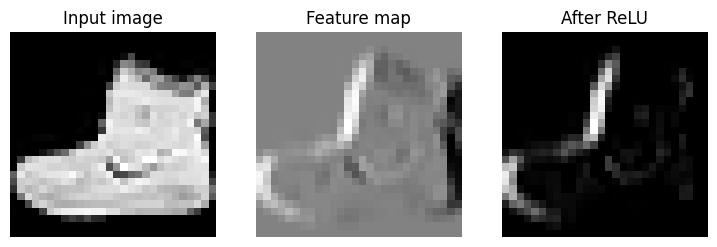

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(image[0, :, :, 0], cmap="gray"); axes[0].set_title("Input image")
axes[1].imshow(feature[0, :, :, 0], cmap="gray"); axes[1].set_title("Feature map")
axes[2].imshow(activated[0, :, :, 0], cmap="gray"); axes[2].set_title("After ReLU")
for ax in axes: ax.axis("off")
plt.show()

**Filter yang dipelajari CNN**

In [6]:
# Conv2D dengan beberapa filter yang diinisialisasi secara acak
conv_layer = layers.Conv2D(8, kernel_size=3, padding="same", activation="relu")
feature_maps = conv_layer(image)

print("Input shape:", image.shape)
print("Feature maps shape:", feature_maps.shape)

Input shape: (1, 28, 28, 1)
Feature maps shape: (1, 28, 28, 8)


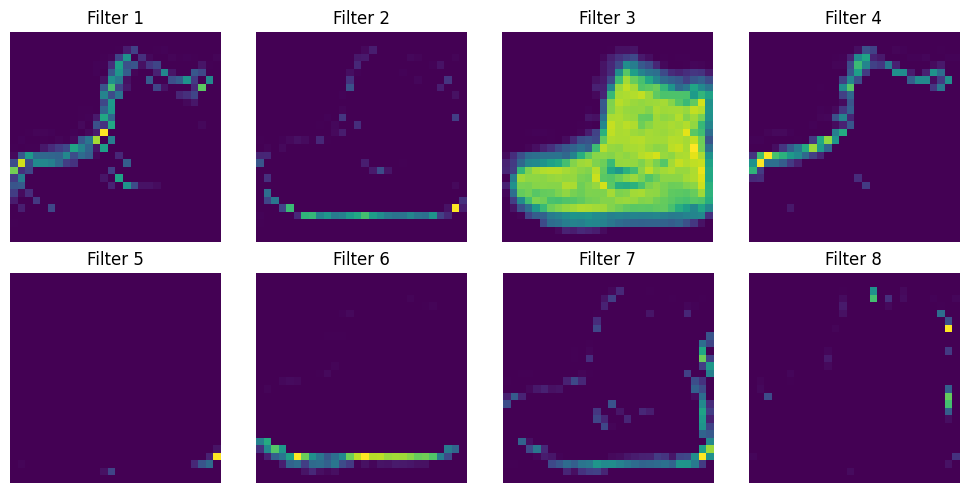

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()